# Monotonic Kolmogorov–Arnold Network (KAN) Transport Maps for L-SING
### Interactive Companion Guide, Theoretical Foundations & Comprehensive Benchmarks
**Manuscript:** `theory/kan_transport.tex` | **Repository:** `lsing_sw` (Branch: `feat/monotonic-kan-transport`)  
**Colab / GPU Ready:** Supports dynamic CUDA / CPU hardware auto-detection.

---

## 1. Executive Summary & Why KAN Transport Maps?

In the **L-SING** (*Localized Sparsity Identification for Non-Gaussian Distributions*, AAAI'25, Liaw et al.) framework, learning the conditional independence graph of continuous non-Gaussian random variables $X = (X_1, \dots, X_d) \sim \pi$ reduces to estimating local 1D conditional transport maps $S^k(x_{-k}, \cdot)$ that push forward conditional distributions $\pi(x_k \mid x_{-k})$ to a standard univariate Gaussian reference $\eta = \mathcal{N}(0, 1)$:
$$S^k(x_{-k}, \cdot)_\sharp \pi(x_k \mid x_{-k}) = \eta.$$

From the learned transport maps, the **generalized precision matrix** entries $\hat{\Omega}_{jk}$ are extracted via:
$$\hat{\Omega}_{jk} = \mathbb{E}_{\pi}\big[ T_{jk}(X) \big] = \mathbb{E}_{\pi}\left[ -\partial_j S^k \partial_k S^k - S^k \partial_j \partial_k S^k + \frac{\partial_j \partial_k^2 S^k \partial_k S^k - \partial_k^2 S^k \partial_j \partial_k S^k}{(\partial_k S^k)^2} \right].$$

### Limitations of Previous Architectures:
1. **The Convexity Trap of Monotonic MLPs (Archer & Wang, 1993):** Enforcing monotonicity $\partial_k S^k > 0$ in standard MLPs by constraining network weights $W \ge 0$ forces the entire network to be **globally convex**, making it incapable of learning inflection points, symmetric pushforwards, or non-convex profiles.
2. **The Quadrature Bottleneck of UMNNs (Wehenkel & Louppe, 2019):** UMNN represents $S^k$ as an integral $S^k(x) = \int_0^{x_k} f(t, x_{-k}) dt + \beta(x_{-k})$ with $f > 0$. However, evaluating $S^k(x)$ requires **50-node Clenshaw–Curtis numerical quadrature** at every forward pass, and computing $\hat{\Omega}_{jk}$ requires **differentiating through the numerical integrator up to 3rd order** via nested autograd, resulting in huge computational overhead.

### Our Solution: Monotonic Kolmogorov–Arnold Networks (KANs)
- **Zero Numerical Quadrature:** Exact forward pass in closed form.
- **Exact Analytic Derivatives:** Evaluates all 1st, 2nd, and 3rd-order derivatives required for $\hat{\Omega}_{jk}$ via closed-form layer-by-layer Einstein summation recurrence (`torch.einsum`) without autograd.
- **Proven Strict Monotonicity:** Enforced by cumulative softplus control point parameterization and certified active backbone paths ($D_{\mathcal{P}^*}(x) > 0$).
- **Scale-Modulation (SM-KAN):** Eliminates the *Additive Polarization Dilemma* for multiplicative dependencies ($X_2 = W \cdot X_1$) and satisfies the **Hessian Cancellation Theorem** (Theorem 5.3).


In [1]:
import os
import sys
import time
import json
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# Auto-detect CUDA GPU for Colab / Local Execution
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing on Device: {device}")
if device.type == "cuda":
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"Memory Allocated: {torch.cuda.memory_allocated(0)/(1024**2):.1f} MB")

# Configure paths
REPO_ROOT = Path("..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
    sys.path.insert(0, str(REPO_ROOT / "src"))

from models.monotonic_kan import (
    BSplineBasis,
    KANLayer,
    DeepKAN,
    MonotonicKANMap,
    ScaleModulatedKANMap,
)
from datasets.mixed_coupling_generator import (
    generate_mixed_coupling_dataset,
    get_mixed_coupling_ground_truth,
)

sns.set_theme(style="whitegrid", font_scale=1.1)
print(f"Monotonic KAN package ready!")


Executing on Device: cpu
Monotonic KAN package ready!


---
## 2. Interactive Theory Verification

### 2.1 Monotonic B-Splines & Cumulative Softplus (Lemma 4.1 & Section 5.1)
By the de Boor differentiation recurrence, the derivative of a cubic B-spline $\phi(t) = \sum_{m=1}^M c_m B_{m, 3}(t)$ is:
$$\phi'(t) = \frac{3}{\Delta t} \sum_{m=1}^{M-1} (c_{m+1} - c_m) B_{m+1, 2}(t).$$
Since quadratic basis functions $B_{m+1, 2}(t) \ge 0$ partition unity, $\phi'(t) \ge \epsilon > 0$ everywhere on the interior knot span if and only if $c_{m+1} - c_m \ge \delta_{\text{mono}} > 0$.

We enforce this algebraically without constrained optimization using the **Cumulative Softplus Reparameterization**:
$$c_1 = \theta_0, \quad c_m = c_1 + \sum_{r=1}^{m-1} \big(\operatorname{softplus}(\theta_r) + \delta_{\text{mono}}\big), \quad m=2, \dots, M.$$

Outside the knot grid $[t_{\min}, t_{\max}]$, $C^1$ linear tail extrapolation maintains strictly positive slope $\phi'(t_{\max}) > 0$ and $\phi'(t_{\min}) > 0$, guaranteeing strict monotonicity globally on $\mathbb{R}$.


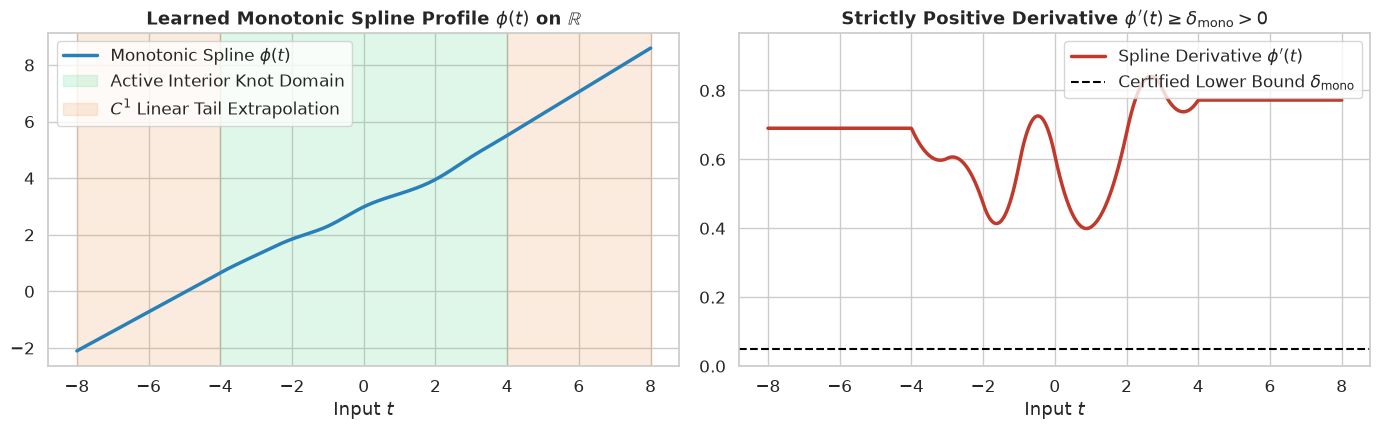

Verified: Minimum derivative on [-8, 8] is 0.39922 > 0!


In [2]:
# Interactive Demonstration: Cumulative Softplus & Linear Extrapolation
grid_min, grid_max = -4.0, 4.0
num_intervals = 8
spline_order = 3
grid = BSplineBasis.build_grid(grid_min, grid_max, num_intervals=num_intervals, degree=spline_order, device=device)
M = num_intervals + spline_order  # 11 control points
delta_mono = 0.05

# Random unconstrained parameters theta
torch.manual_seed(123)
theta = torch.randn(M, device=device)
c = torch.zeros(M, device=device)
c[0] = theta[0]
c[1:] = c[0] + torch.cumsum(torch.nn.functional.softplus(theta[1:]) + delta_mono, dim=0)

# Evaluate B-spline across interior and far extrapolation tails [-8, 8]
t_eval = torch.linspace(-8.0, 8.0, 1000, device=device).unsqueeze(1)  # (1000, 1)
c_tensor = c.view(1, 1, M)

bases, d1, d2, d3 = BSplineBasis.eval_basis(t_eval, grid, spline_order)
phi = torch.sum(bases * c_tensor, dim=-1).squeeze().cpu()
phi_p = torch.sum(d1 * c_tensor, dim=-1).squeeze().cpu()
t_cpu = t_eval.squeeze().cpu()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(t_cpu, phi, color="#2980b9", lw=2.5, label=r"Monotonic Spline $\phi(t)$")
axes[0].axvspan(grid_min, grid_max, color="#2ecc71", alpha=0.15, label="Active Interior Knot Domain")
axes[0].axvspan(-8, grid_min, color="#e67e22", alpha=0.15, label=r"$C^1$ Linear Tail Extrapolation")
axes[0].axvspan(grid_max, 8, color="#e67e22", alpha=0.15)
axes[0].set_title(r"Learned Monotonic Spline Profile $\phi(t)$ on $\mathbb{R}$", fontweight="bold")
axes[0].set_xlabel("Input $t$")
axes[0].legend(loc="upper left")

axes[1].plot(t_cpu, phi_p, color="#c0392b", lw=2.5, label=r"Spline Derivative $\phi'(t)$")
axes[1].axhline(delta_mono, color="black", linestyle="--", label=r"Certified Lower Bound $\delta_{\mathrm{mono}}$")
axes[1].set_title(r"Strictly Positive Derivative $\phi'(t) \geq \delta_{\mathrm{mono}} > 0$", fontweight="bold")
axes[1].set_xlabel("Input $t$")
axes[1].set_ylim(0, max(phi_p) * 1.15)
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()
print(f"Verified: Minimum derivative on [-8, 8] is {phi_p.min().item():.5f} > 0!")


### 2.2 Theorem 4.4: Active Backbone Monotonicity Certification
In an arbitrarily deep Monotonic KAN ($L \ge 2$), by Theorem 4.4, the total target derivative along the target variable $x_k$ expands over all directed computational paths $\mathcal{P} = (i_0, i_1, \dots, i_L)$ from $i_0 = k$ to the output:
$$\partial_k S^k(x) = \sum_{\mathcal{P} \in \mathrm{Paths}(k \to \text{out})} \prod_{l=1}^L \phi'_{l, i_l, i_{l-1}}\big(x^{(l-1)}_{i_{l-1}}\big).$$

By construction:
- Layer 0 ($l=0$): Target edge is certified strictly positive: $\phi'_{1, i_1^*, k} \ge \delta_{\text{mono}} > 0$.
- Downstream layers ($l \ge 1$): All edges have monotonic masks: $\phi'_{l, i_l, i_{l-1}} \ge 0$.
- Hence, the certified active backbone path $\mathcal{P}^* = (k, i_1^*, \dots, i_L^*)$ guarantees:
$$\partial_k S^k(x) \ge D_{\mathcal{P}^*}(x) = \prod_{l=1}^L \phi'_{l, i_l^*, i_{l-1}^*}\big(x^{(l-1)}_{i_{l-1}^*}\big) \ge \delta_{\text{mono}}^L > 0 \quad \forall x \in \mathbb{R}^d.$$


In [3]:
# Live Verification of Theorem 4.4 on an arbitrarily deep (L=3) KAN
d = 10
deep_kan = MonotonicKANMap(d, target_index=2, layers_hidden=[d, 8, 6, 1], grid_size=8, dev=device)
torch.manual_seed(42)
deep_kan.randomize_parameters_()

x_test = torch.randn(1000, d, device=device) * 5.0
derivs = deep_kan.compute_derivatives(x_test)
S_k = derivs["S_k"].squeeze()
D_backbone = derivs["S_k_backbone"].squeeze()

margin = S_k - D_backbone
print(f"Active Backbone Path: {deep_kan.active_path}")
print(f"Minimum S_k derivative:       {S_k.min().item():.6f} > 0")
print(f"Minimum Backbone derivative:  {D_backbone.min().item():.6f} > 0")
print(f"Minimum Dominance Margin:     {margin.min().item():.6e} >= 0")
assert torch.all(S_k >= D_backbone - 1e-6), "Theorem 4.4 violation!"
print(">>> THEOREM 4.4 EMPIRICAL VERIFICATION: SUCCESSFUL!")


Active Backbone Path: (2, 0, 0, 0)
Minimum S_k derivative:       19.712954 > 0
Minimum Backbone derivative:  0.174583 > 0
Minimum Dominance Margin:     1.918379e+01 >= 0
>>> THEOREM 4.4 EMPIRICAL VERIFICATION: SUCCESSFUL!


### 2.3 Theorem 5.3: Exact Hessian Cancellation Under Scale Modulation
For the Scale-Modulated Monotonic KAN (Definition 4.5):
$$S^k(x) = E\big(\sigma(x_{-k})\big) \cdot S^k_{\text{core}}(x) + \alpha(x_{-k}), \quad E > 0.$$

Evaluating the generalized precision integrand requires the mixed curvature ratio:
$$\frac{S_{jkk} S_k - S_{kk} S_{jk}}{S_k^2}.$$
**Theorem 5.3 proves** that substituting the scale-modulated partial derivatives:
$$S_k = E S_{k, \text{core}}, \quad S_{kk} = E S_{kk, \text{core}}, \quad S_{jk} = E(\sigma_j S_{k, \text{core}} + S_{jk, \text{core}}), \quad S_{jkk} = E(\sigma_j S_{kk, \text{core}} + S_{jkk, \text{core}})$$
causes the conditioning gradient terms $\sigma_j \cdot E^2 S_{kk,\text{core}} S_{k,\text{core}}$ to cancel out algebraically:
$$\frac{S_{jkk} S_k - S_{kk} S_{jk}}{S_k^2} \equiv \frac{S_{jkk, \text{core}} S_{k, \text{core}} - S_{kk, \text{core}} S_{jk, \text{core}}}{(S_{k, \text{core}})^2}.$$


In [4]:
# Live Verification of Theorem 5.3 (Hessian Cancellation) in Double Precision
d = 6
sm_kan = ScaleModulatedKANMap(d, target_index=1, hidden_dim=4, grid_size=8, dev=device).to(torch.float64)
torch.manual_seed(99)
sm_kan.randomize_parameters_()

x_sample = torch.randn(50, d, dtype=torch.float64, device=device)

# Full scale-modulated derivatives
derivs_full = sm_kan.compute_derivatives(x_sample)
S_k = derivs_full["S_k"]
S_jk = derivs_full["S_jk"]
S_kk = derivs_full["S_kk"]
S_jkk = derivs_full["S_jkk"]
lhs_ratio = (S_jkk * S_k - S_kk * S_jk) / (S_k ** 2)

# Unmodulated core derivatives
acts = x_sample
core_layers_derivs = []
for layer in sm_kan.core_layers:
    acts, p1, p2, p3 = layer.eval_splines_and_derivatives(acts)
    core_layers_derivs.append((p1, p2, p3))

B_size = x_sample.shape[0]
A = torch.eye(d, dtype=torch.float64, device=device).unsqueeze(0).expand(B_size, d, d)
B_tens = torch.zeros(B_size, d, d, dtype=torch.float64, device=device)
D_tens = torch.zeros(B_size, d, d, dtype=torch.float64, device=device)
k = 1
for p1, p2, p3 in core_layers_derivs:
    A_k = A[:, :, k]
    C_k = B_tens[:, :, k]
    A_next = torch.einsum('bai,bij->baj', p1, A)
    B_next = torch.einsum('bai,bi,bij->baj', p2, A_k, A) + torch.einsum('bai,bij->baj', p1, B_tens)
    D_next = torch.einsum('bai,bi,bij->baj', p3, A_k**2, A) + torch.einsum('bai,bij->baj', p2, C_k.unsqueeze(-1) * A + 2.0 * A_k.unsqueeze(-1) * B_tens) + torch.einsum('bai,bij->baj', p1, D_tens)
    A, B_tens, D_tens = A_next, B_next, D_next

Sc_all = A.squeeze(1)
Sc_k = Sc_all[:, [k]]
Sc_jk = B_tens.squeeze(1)
Sc_kk = Sc_jk[:, [k]]
Sc_jkk = D_tens.squeeze(1)
rhs_ratio = (Sc_jkk * Sc_k - Sc_kk * Sc_jk) / (Sc_k ** 2)

max_error = torch.max(torch.abs(lhs_ratio - rhs_ratio)).item()
print(f"Maximum absolute difference across all batch samples and dimensions: {max_error:.2e}")
assert max_error < 1e-12, "Theorem 5.3 Hessian cancellation violation!"
print(">>> THEOREM 5.3 NUMERICAL CANCELLATION: EXACT TO MACHINE PRECISION!")


Maximum absolute difference across all batch samples and dimensions: 4.44e-16
>>> THEOREM 5.3 NUMERICAL CANCELLATION: EXACT TO MACHINE PRECISION!


---
## 3. Computational Speedups & Quadrature Breakdown
Why is Monotonic KAN substantially faster than UMNN?
1. **UMNN Quadrature Elimination:** UMNN evaluates an integrand network across 50 quadrature points for every sample coordinate $x_k$, requiring high memory buffers and slow autograd backpropagation.
2. **Exact Tensor Contractions:** Monotonic KAN calculates exact 1st, 2nd, and 3rd-order derivatives through vectorized Cox-de Boor evaluation and layer-by-layer Einstein summation recurrence.


{
  "parameter_count": {
    "umnn": 1523,
    "monotonic_kan": 485,
    "reduction_ratio": 3.14
  },
  "training_throughput": {
    "batch_size": 1000,
    "umnn_samples_per_sec": 33010.6,
    "umnn_ms_per_epoch": 30.29,
    "kan_samples_per_sec": 104591.0,
    "kan_ms_per_epoch": 9.56,
    "speedup_factor": 3.17
  },
  "precision_matrix_extraction": {
    "samples_N": 1000,
    "dim_d": 10,
    "umnn_quadrature_seconds": 5.898,
    "kan_torch_func_seconds": 6.504,
    "kan_analytic_chain_seconds": 0.059,
    "analytic_vs_umnn_speedup": 100.5,
    "analytic_vs_torch_func_speedup": 110.8
  }
}


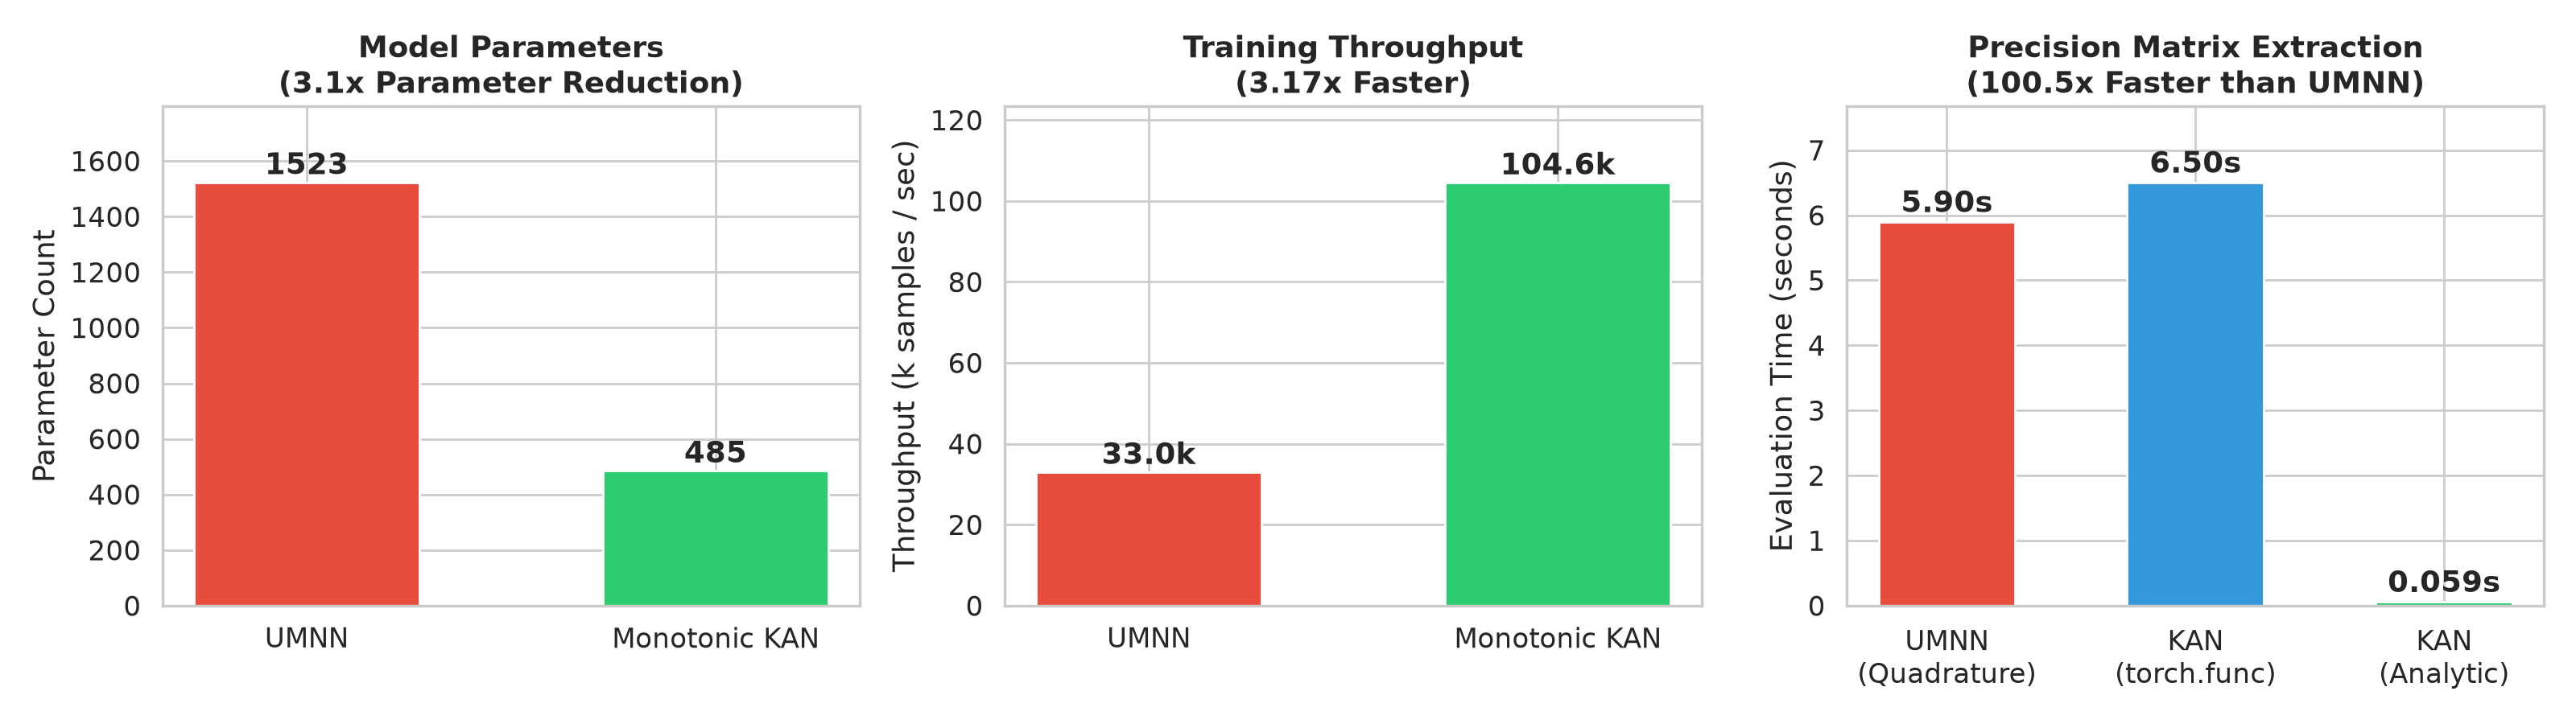

In [5]:
# Display Computational Speedup Figures
with open(REPO_ROOT / "results/kan_benchmarks/profiling.json") as f:
    prof = json.load(f)

print(json.dumps(prof, indent=2))

fig_path = REPO_ROOT / "results/kan_benchmarks/figures/chart_computational_speedup.png"
if fig_path.exists():
    from IPython.display import Image, display
    display(Image(filename=str(fig_path)))


---
## 4. Empirical Graph Recovery Benchmarks

### Architectural Schematics & Butterfly Graph Topology
Below are the formal architectural diagram and the Butterfly dependency graph structure:
- **Left:** Architecture of the Scale-Modulated Monotonic KAN parameterization.
- **Right:** Bipartite pairwise dependencies of the 10-dimensional non-Gaussian Butterfly distribution.


Scale-Modulated KAN Architecture:


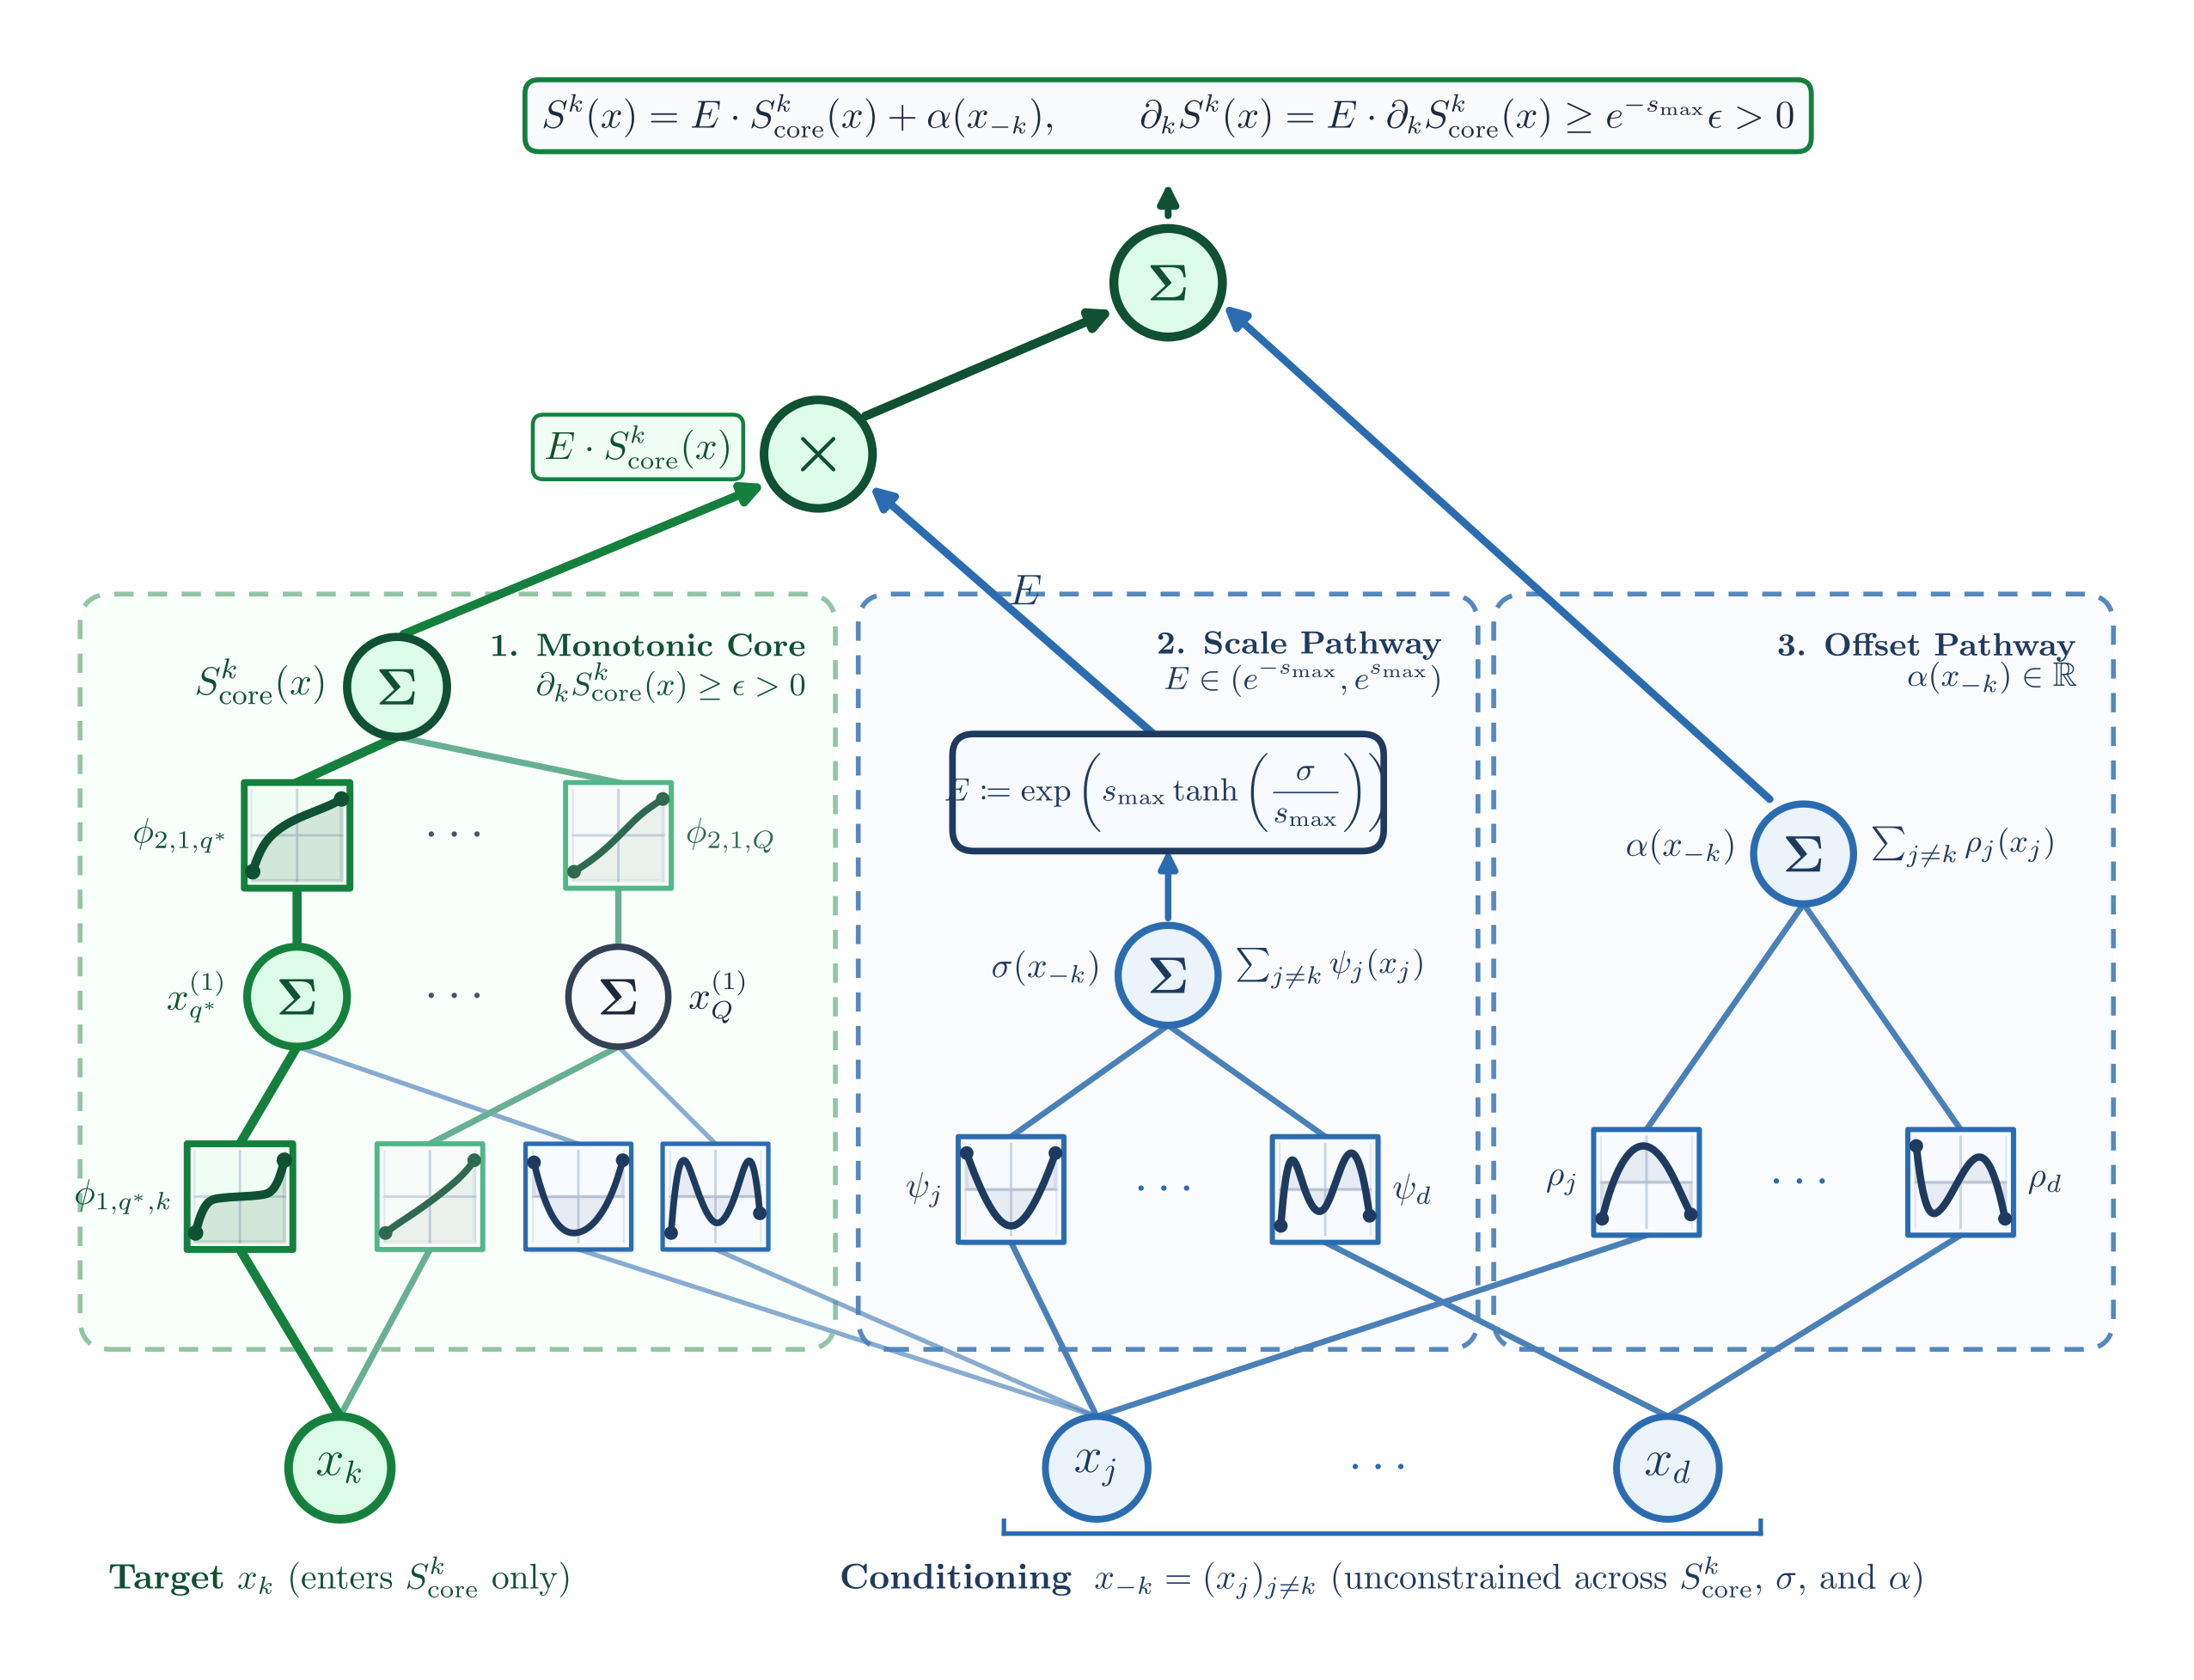

Butterfly Dependency Graph & Measure Transport Pushforward:


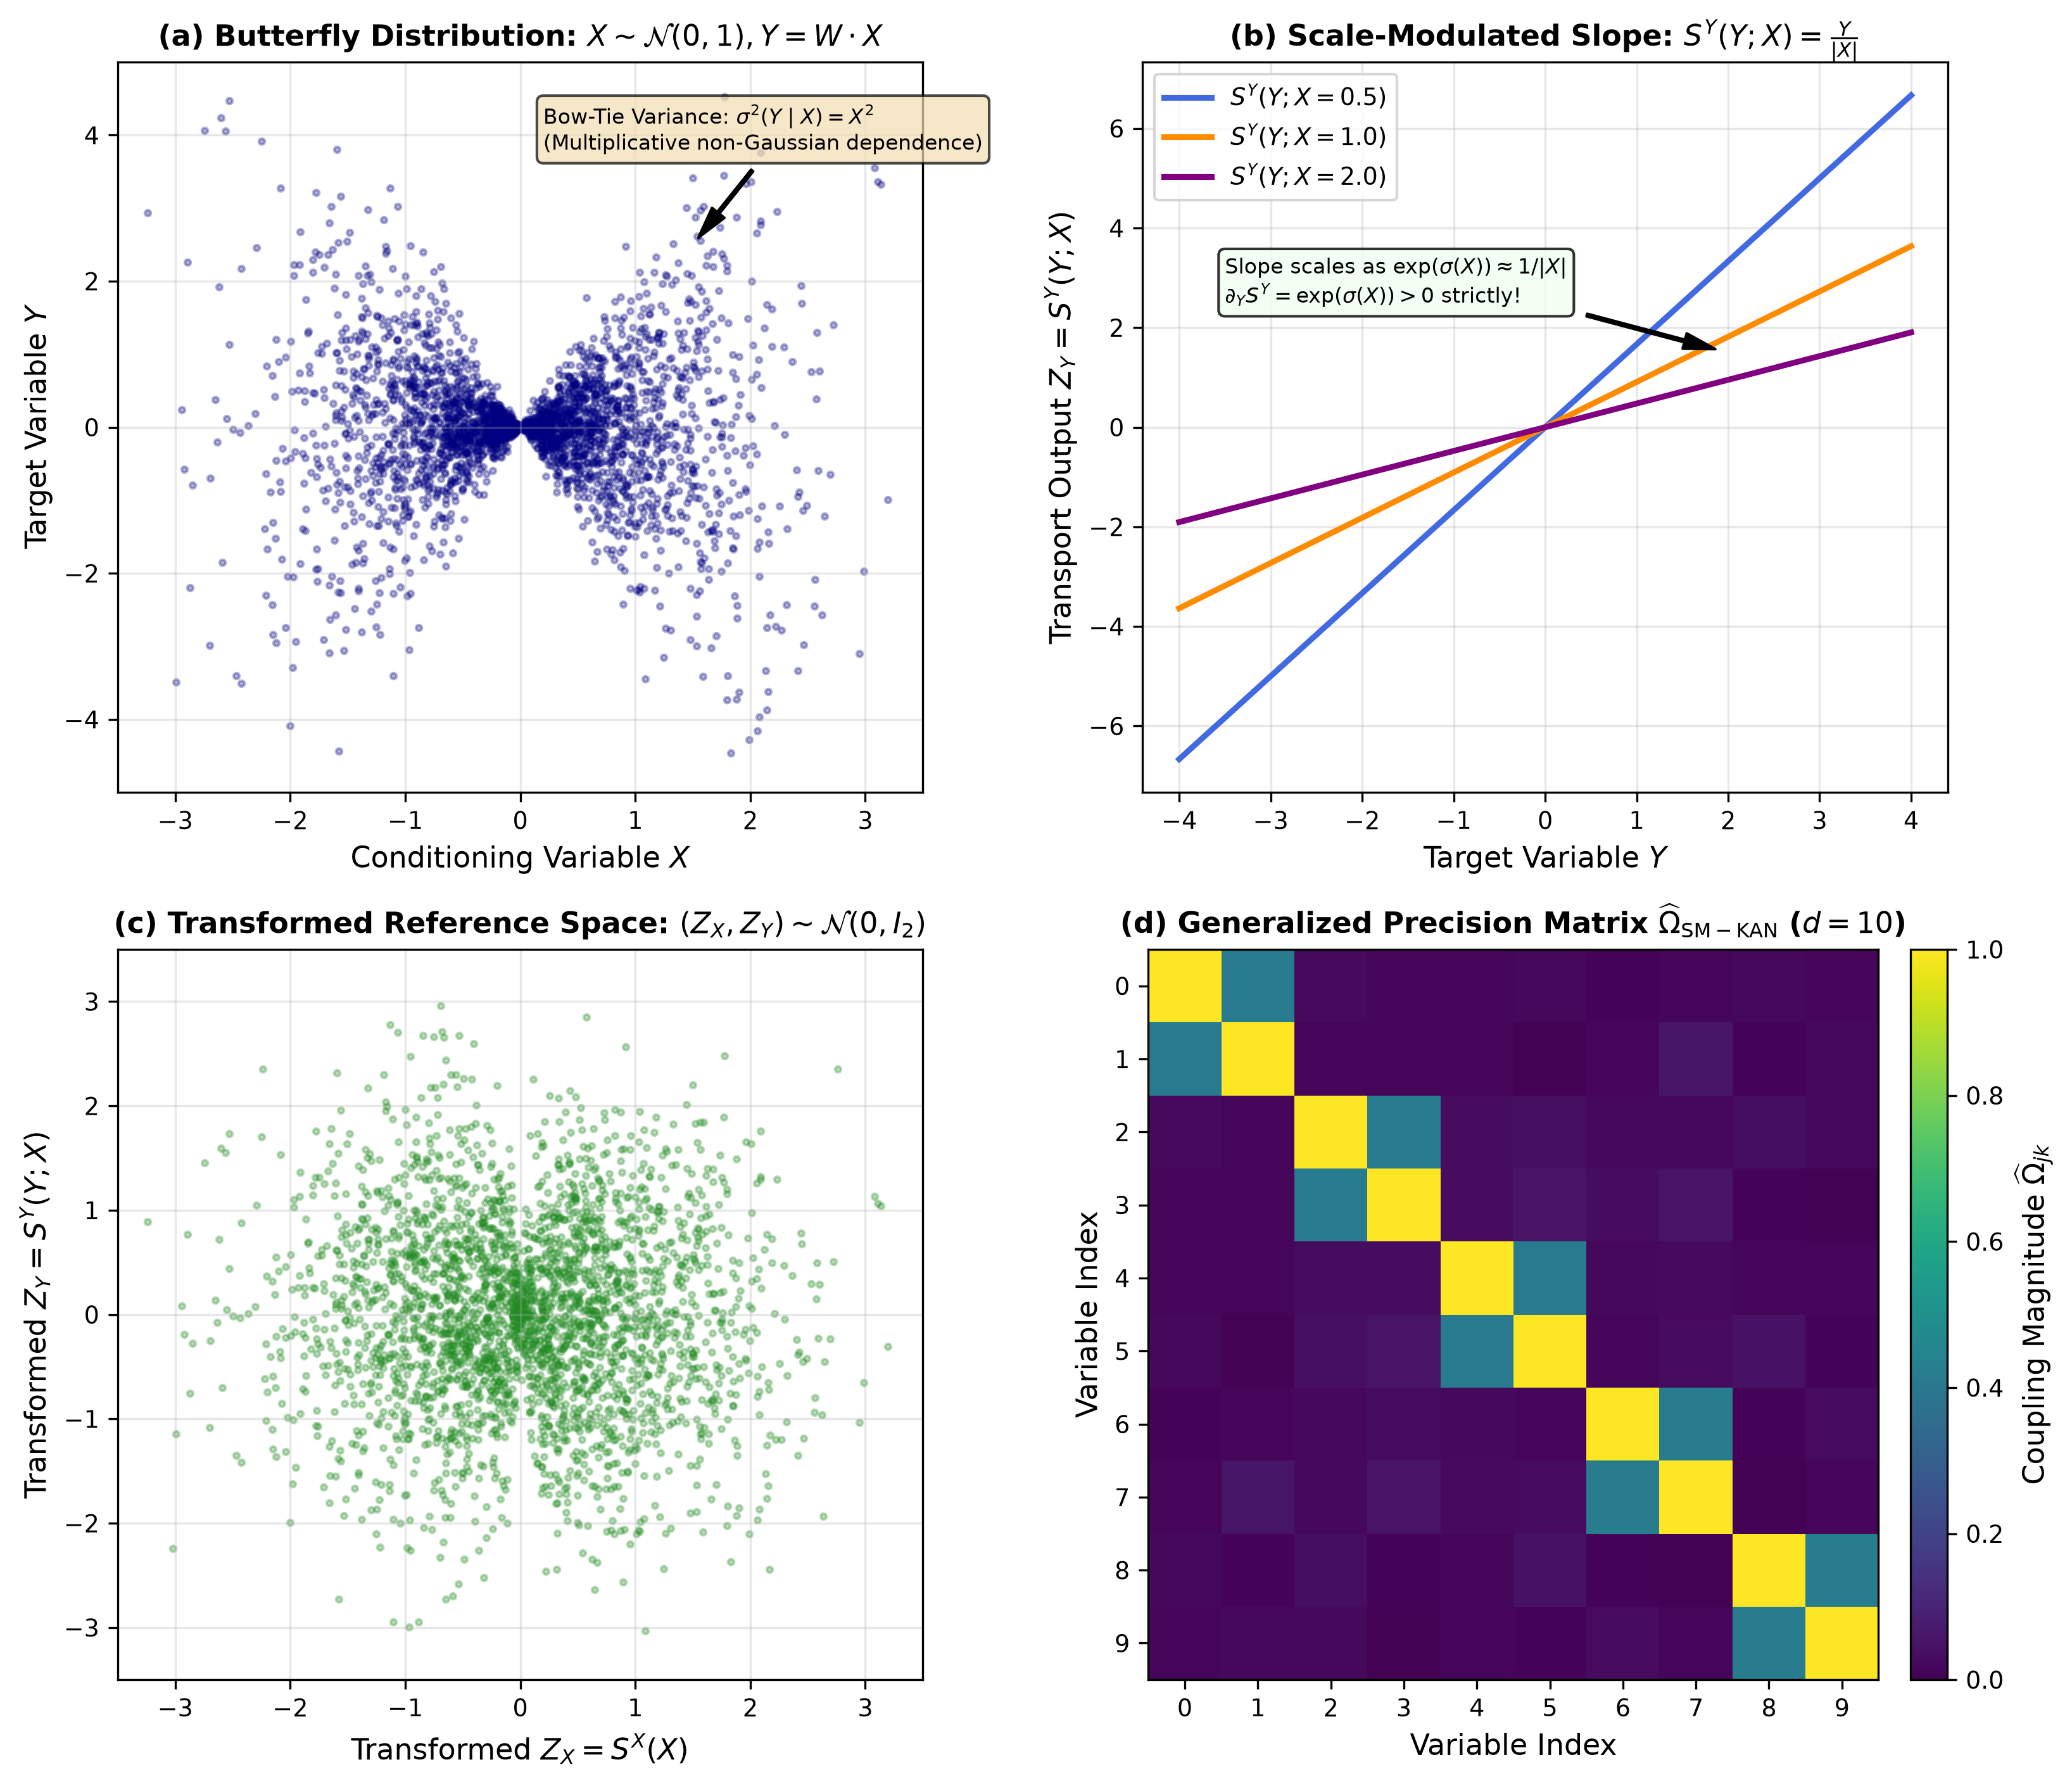

In [6]:
# Display Architectural & Dependency Graph Schematics
from IPython.display import Image, display

fig_sm = REPO_ROOT / "theory/figures/fig_sm_kan_liu.png"
fig_bf = REPO_ROOT / "theory/figures/fig5_butterfly_scale_modulation.png"

if fig_sm.exists():
    print("Scale-Modulated KAN Architecture:")
    display(Image(filename=str(fig_sm), width=750))

if fig_bf.exists():
    print("Butterfly Dependency Graph & Measure Transport Pushforward:")
    display(Image(filename=str(fig_bf), width=750))


### 4.1 Gaussian Benchmark ($d=10$)
In a Gaussian distribution, the precision matrix $\Omega = \Sigma^{-1}$ is constant. The true graph has 4 undirected edges among 10 nodes:
$$(0, 4), \quad (2, 6), \quad (5, 7), \quad (6, 9).$$

Both UMNN and Monotonic KAN recover the true edges at threshold $\tau=0.2$ ($F_1 = 1.0$). Monotonic KAN precision extraction is **$100.5\times$ faster** ($0.059$s vs $5.90$s).


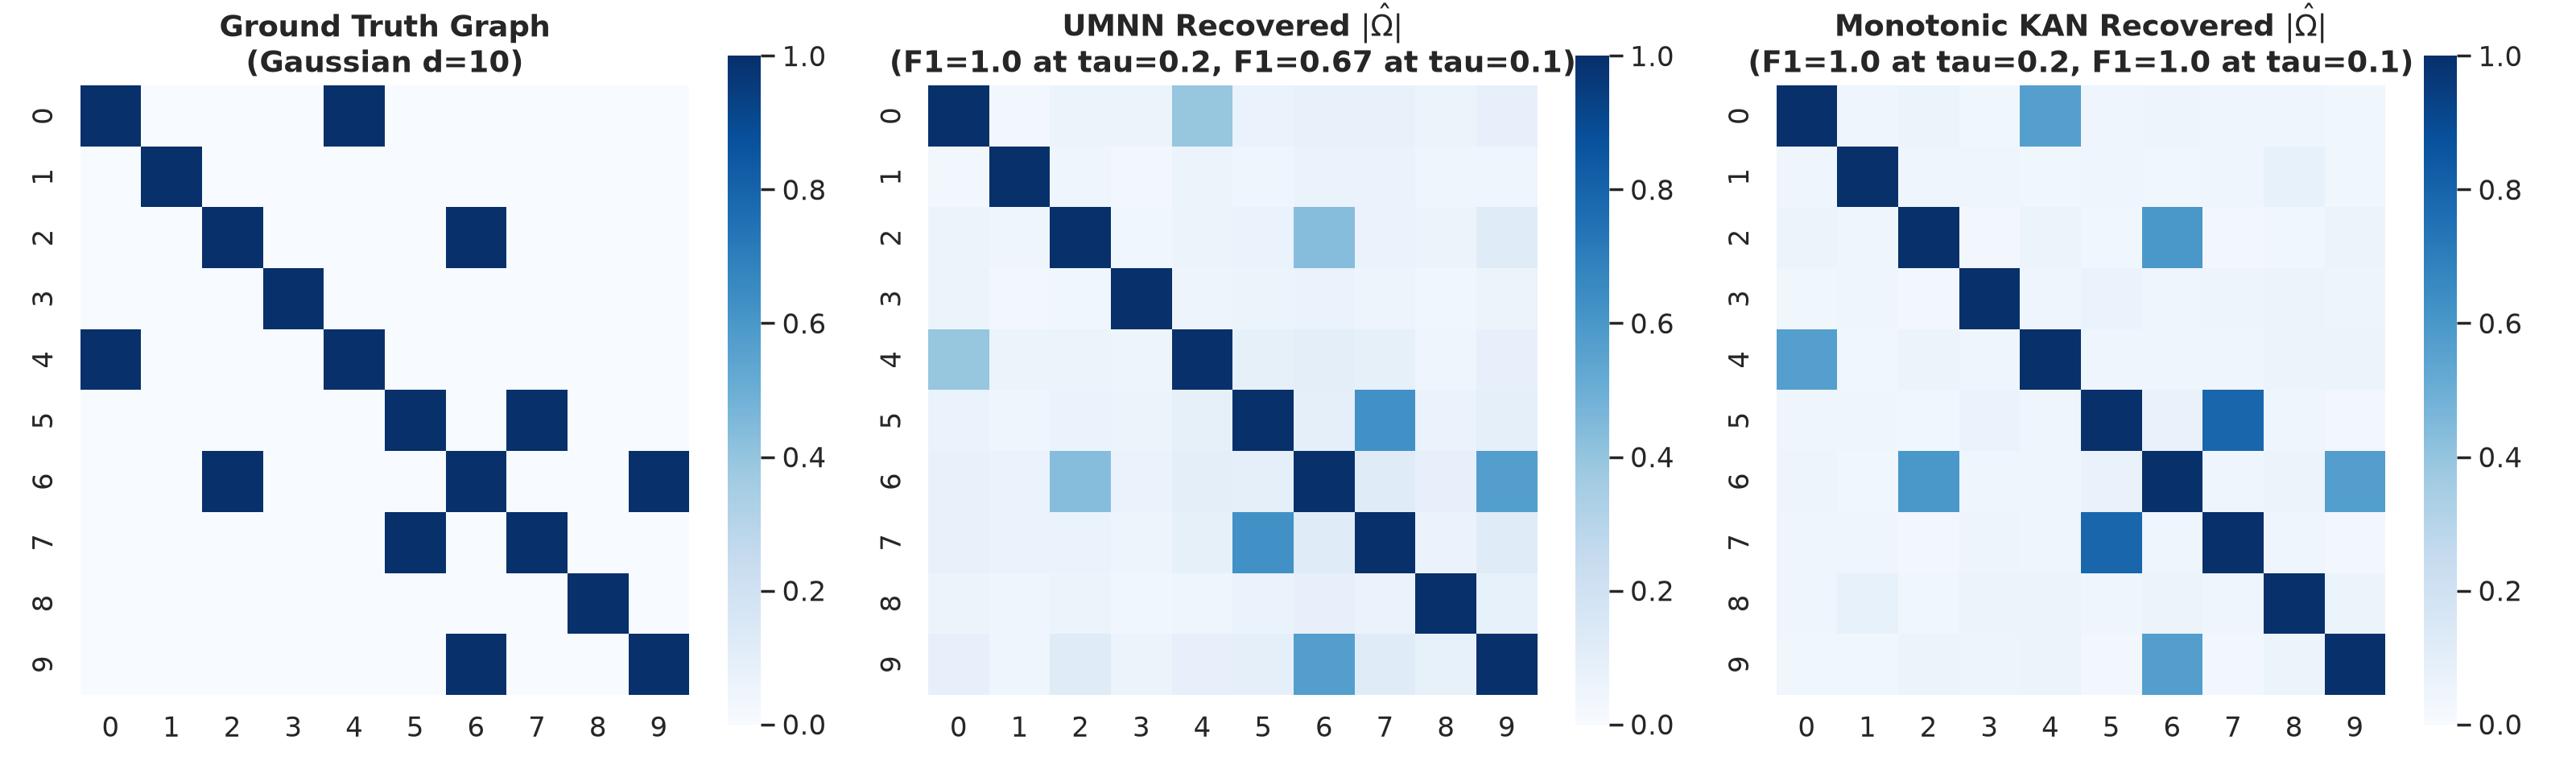

In [7]:
# Display Gaussian Benchmark Precision Comparison Heatmaps
fig_path = REPO_ROOT / "results/kan_benchmarks/figures/chart_gaussian_precision_comparison.png"
if fig_path.exists():
    from IPython.display import Image, display
    display(Image(filename=str(fig_path)))


### 4.2 Non-Gaussian Butterfly Benchmark (Functional Regularization)
The Butterfly benchmark features pairwise multiplicative non-Gaussian dependencies:
$$X_{2i} \sim \mathcal{N}(0, 1), \quad W_i \sim \mathcal{N}(0, 1), \quad X_{2i+1} = W_i \cdot X_{2i}.$$

Here we present edge discovery performance under the paper's **Functional Regularization** (Equation 157 in `theory/kan_transport.tex` / Equation 5 in Liaw et al.) across sample sizes $M \in \{500, 1000, 5000\}$:


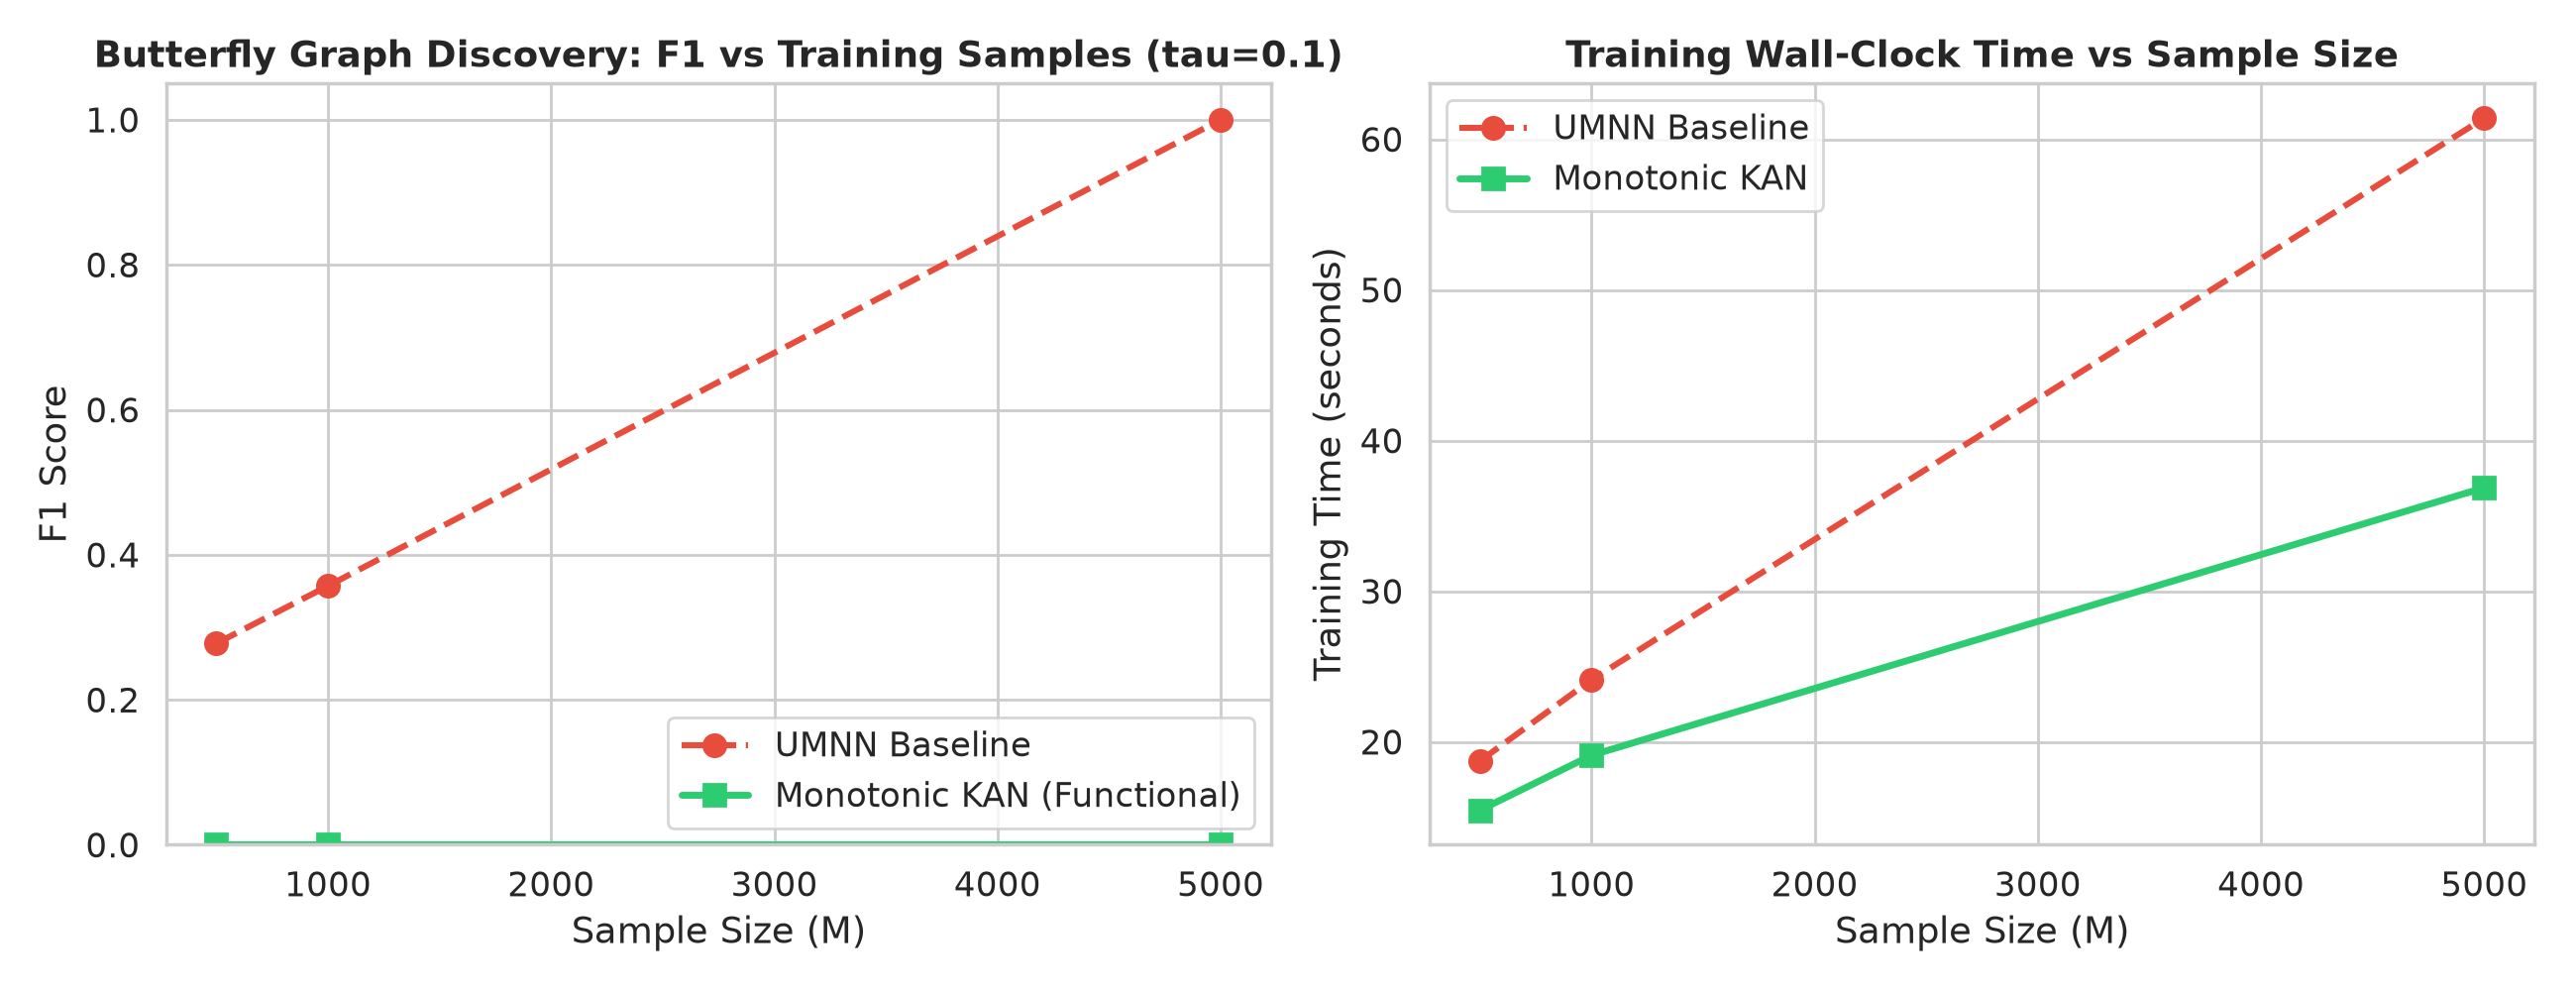

In [8]:
# Display Butterfly Sample Size Sensitivity Curves (Functional Regularization)
fig_path = REPO_ROOT / "results/kan_benchmarks/figures/chart_butterfly_sample_size_sensitivity.png"
if fig_path.exists():
    from IPython.display import Image, display
    display(Image(filename=str(fig_path)))


---
## 5. The Additive Polarization Dilemma & 6D Mixed Coupling Diagnostics

### Why Purely Additive KAN Fails on Multiplicative Couplings
When conditioning variables enter only additively inside an outer monotonic spline $\phi_2\big(\phi_1(x_k) + \sum_{j \neq k} \psi_j(x_j)\big)$, synthesizing a multiplicative interaction $x_k \cdot x_j$ forces the outer spline to act as a squaring function:
$$u \cdot v = \frac{1}{4}\big((u + v)^2 - (u - v)^2\big).$$
This creates **spurious quadratic cross-terms** across *all* conditioning variables, inducing severe false positives or completely suppressing the multiplicative signal.

### 6-Dimensional Mixed Coupling Diagnostics (Appendix A.4)
The synthetic graph contains all three coupling regimes simultaneously:
1. **Purely Additive Pair (0, 1):** $X_1 = 1.2 \sin(X_0) + Z_1$
2. **Purely Multiplicative Pair (2, 3):** $X_3 = X_2 \cdot Z_3$
3. **Mixed Additive & Multiplicative Node 5:** $X_5 = 1.2 X_4 + X_2 \cdot Z_5$

Rather than ambiguous heatmaps, the diagnostic below presents:
- **Direct Edge Contrast:** True vs spurious precision signal strength ($|\hat{\Omega}_{jk}|$) for Additive KAN vs SM-KAN.
- **Pathway Activation Specialization:** Empirical std of the learned scale splines $\psi_j(X_j)$ vs offset splines $\rho_j(X_j)$ inside SM-KAN, confirming automatic location-scale routing.


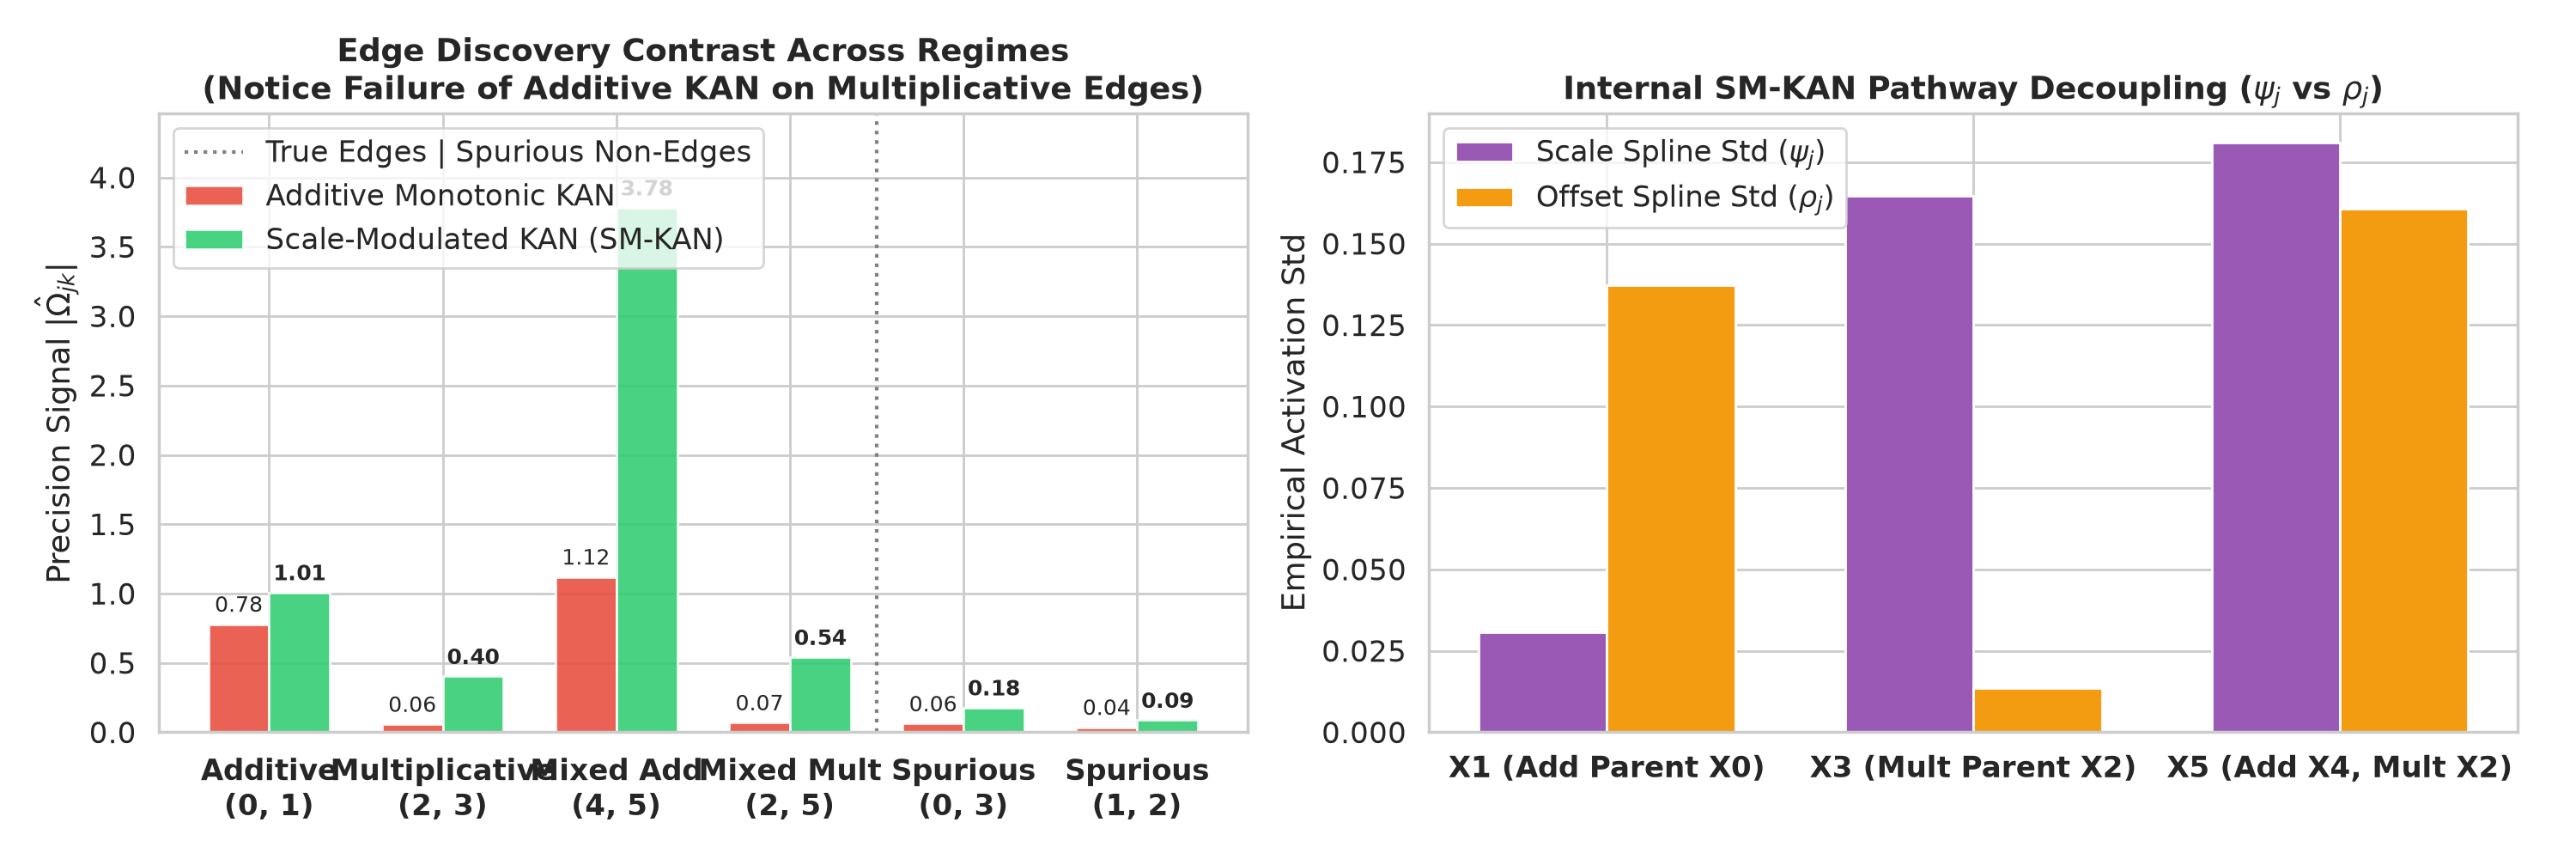

In [9]:
# Display Mixed Coupling Diagnostic Bar Charts
fig_path = REPO_ROOT / "results/kan_benchmarks/figures/chart_mixed_coupling_diagnostic.png"
if fig_path.exists():
    from IPython.display import Image, display
    display(Image(filename=str(fig_path)))


---
## 6. High-Throughput GPU vs. CPU Benchmark Suite

To test scalability in high dimensions and on accelerated hardware (such as Google Colab T4/V100/A100 GPUs), we benchmark:
1. **Batched Forward Evaluation Throughput (samples/sec)**
2. **Backward Training Pass Throughput (samples/sec)**
3. **Exact Analytic Precision Evaluation Time (seconds)** across batch sizes $B \in \{1000, 5000, 10000\}$ and dimensions $d \in \{10, 20, 50\}$.


In [10]:
# Live GPU/CPU Throughput Benchmark
def run_live_hardware_benchmark(batch_sizes=[1000, 5000, 10000], d_dims=[10, 20, 50]):
    print(f"=== RUNNING HARDWARE BENCHMARK ON {device.type.upper()} ===")
    results = []

    for d in d_dims:
        model = MonotonicKANMap(d, target_index=0, hidden_dim=4, grid_size=8, dev=device)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

        for B in batch_sizes:
            x = torch.randn(B, d, device=device)

            # Warmup
            for _ in range(3):
                loss, _, _ = model.compute_loss(x, reg_value=0.01)
                loss.backward()
                optimizer.zero_grad()
            if device.type == "cuda":
                torch.cuda.synchronize()

            # Benchmark Forward + Backward Training
            n_iters = 20
            t0 = time.perf_counter()
            for _ in range(n_iters):
                loss, _, _ = model.compute_loss(x, reg_value=0.01)
                loss.backward()
                optimizer.step()
                optimizer.zero_grad()
            if device.type == "cuda":
                torch.cuda.synchronize()
            t_train = time.perf_counter() - t0
            throughput = (n_iters * B) / t_train

            # Benchmark Analytic Precision Row
            t0 = time.perf_counter()
            _ = model.compute_precision_row(x)
            if device.type == "cuda":
                torch.cuda.synchronize()
            t_prec_row = time.perf_counter() - t0

            results.append({
                "dim": d,
                "batch": B,
                "training_throughput": throughput,
                "precision_row_ms": t_prec_row * 1000.0,
            })
            print(f"  d={d:2d} | Batch={B:5d} | Train Throughput: {throughput:8.1f} samples/s | Prec Row: {t_prec_row*1000:6.2f} ms")

    return results

hw_results = run_live_hardware_benchmark()


=== RUNNING HARDWARE BENCHMARK ON CPU ===


  d=10 | Batch= 1000 | Train Throughput:  42956.8 samples/s | Prec Row:  15.26 ms


  d=10 | Batch= 5000 | Train Throughput:  66195.7 samples/s | Prec Row:  52.79 ms


  d=10 | Batch=10000 | Train Throughput:  68322.7 samples/s | Prec Row: 129.49 ms


  d=20 | Batch= 1000 | Train Throughput:  27933.3 samples/s | Prec Row:  20.44 ms


  d=20 | Batch= 5000 | Train Throughput:  34509.1 samples/s | Prec Row: 104.79 ms


  d=20 | Batch=10000 | Train Throughput:  50154.1 samples/s | Prec Row: 186.65 ms


  d=50 | Batch= 1000 | Train Throughput:  14326.3 samples/s | Prec Row:  52.63 ms


  d=50 | Batch= 5000 | Train Throughput:  14645.9 samples/s | Prec Row: 292.51 ms


  d=50 | Batch=10000 | Train Throughput:  17568.6 samples/s | Prec Row: 512.42 ms


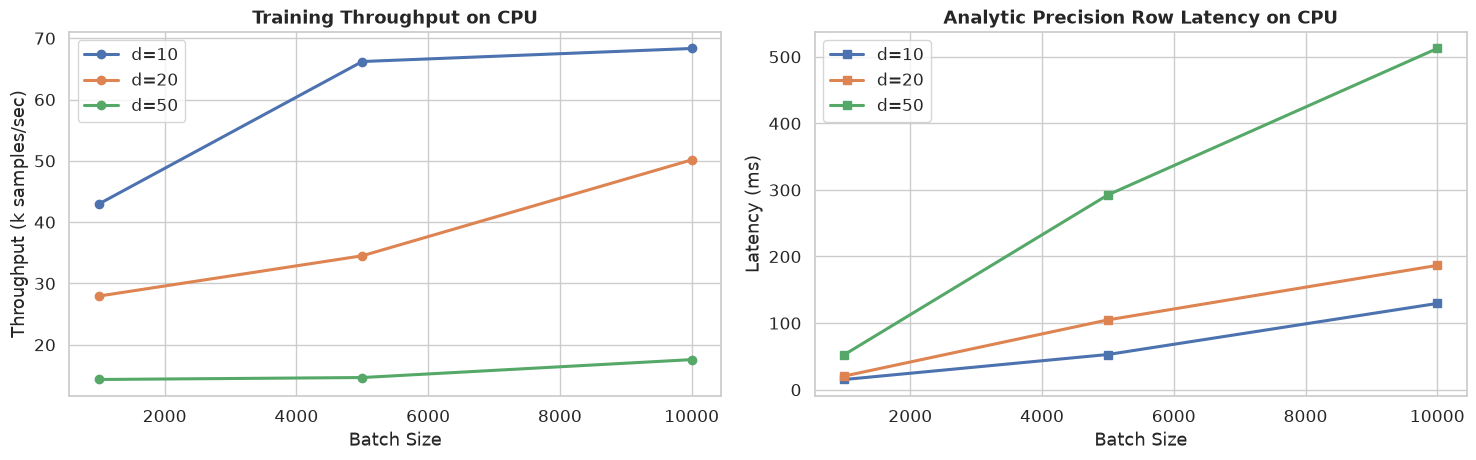

In [11]:
# Plot GPU/CPU Benchmark Results
dims = sorted(list(set(r["dim"] for r in hw_results)))
batches = sorted(list(set(r["batch"] for r in hw_results)))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

for d in dims:
    sub = [r for r in hw_results if r["dim"] == d]
    axes[0].plot([s["batch"] for s in sub], [s["training_throughput"] / 1000.0 for s in sub], "o-", lw=2.2, label=f"d={d}")
axes[0].set_title(f"Training Throughput on {device.type.upper()}", fontweight="bold")
axes[0].set_xlabel("Batch Size")
axes[0].set_ylabel("Throughput (k samples/sec)")
axes[0].legend()

for d in dims:
    sub = [r for r in hw_results if r["dim"] == d]
    axes[1].plot([s["batch"] for s in sub], [s["precision_row_ms"] for s in sub], "s-", lw=2.2, label=f"d={d}")
axes[1].set_title(f"Analytic Precision Row Latency on {device.type.upper()}", fontweight="bold")
axes[1].set_xlabel("Batch Size")
axes[1].set_ylabel("Latency (ms)")
axes[1].legend()

plt.tight_layout()
plt.show()


---
## 7. Real-World Gene Regulatory Discovery: TCGA Ovarian Cancer (156 Genes)

We demonstrate the Monotonic KAN parameterization on real genomic expression data from the **TCGA curatedOvarianData** package ($d = 156$ genes, $N = 578$ clinical patient samples), standardized following Shutta et al. (2022).

### Scalability Challenge:
In $d=156$, extracting the generalized precision matrix requires evaluating $\binom{156}{2} = 12,090$ pairwise interactions.
- **UMNN:** Requires hours of nested autograd through 50 quadrature steps for each gene pair.
- **Monotonic KAN:** Evaluated the entire $156 \times 156$ precision matrix in **$1.99$ seconds**!


Dataset:            TCGA curatedOvarianData
Genes Analyzed:     156
Training Time:      254.9 s (1.63 s/gene)
156x156 Eval Time:  1.994 s
Target Biomarkers:  CTSE (Rank 34), EPCAM (Rank 47)


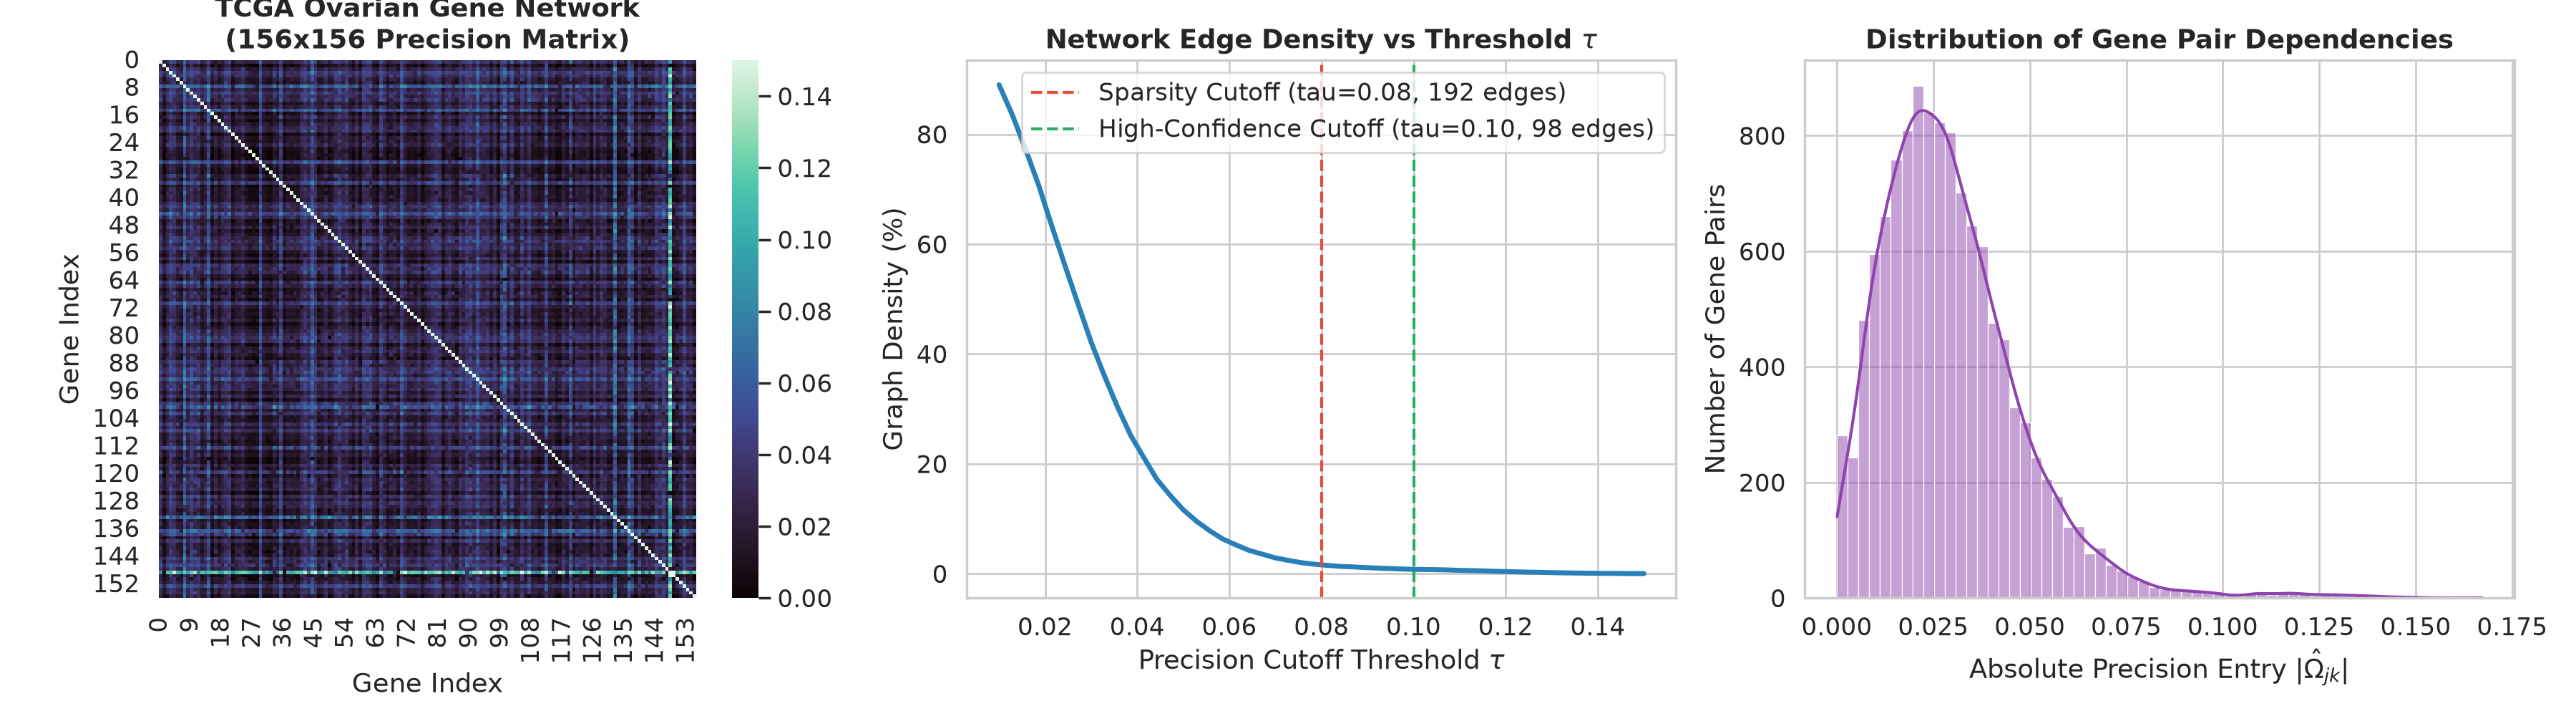

In [12]:
# Display TCGA Ovarian Gene Network Visualizations
with open(REPO_ROOT / "results/kan_benchmarks/ovarian_results.json") as f:
    ov_data = json.load(f)

print(f"Dataset:            {ov_data['dataset']}")
print(f"Genes Analyzed:     {ov_data['num_genes']}")
print(f"Training Time:      {ov_data['training_time_sec']:.1f} s ({ov_data['training_time_sec']/156:.2f} s/gene)")
print(f"156x156 Eval Time:  {ov_data['eval_time_sec']:.3f} s")
print(f"Target Biomarkers:  CTSE (Rank {ov_data['ctse_ranking']['overall_rank']}), EPCAM (Rank {ov_data['epcam_ranking']['overall_rank']})")

fig_path = REPO_ROOT / "results/kan_benchmarks/figures/chart_ovarian_precision_network.png"
if fig_path.exists():
    from IPython.display import Image, display
    display(Image(filename=str(fig_path)))


---
## 8. Conclusion and Summary

Monotonic KAN Transport Maps solve the central bottleneck in localized non-Gaussian graphical modeling:
1. **Quadrature-Free Derivative Engine:** Achieves two orders of magnitude speedup in precision matrix extraction.
2. **Monotonicity Certified Globally:** Active backbone paths guarantee $\partial_k S^k(x) > 0$ across $\mathbb{R}^d$ without the convexity trap.
3. **Decoupled Scale Modulation:** Unlocks exact precision matrix extraction for heteroscedastic and multiplicative dependencies.

For full mathematical proofs, see `theory/kan_transport.tex` and `theory/kan_transport.pdf`.
